# SANPO validation split (chest camera, official train split)

SANPO has only two official splits, train and test. This notebook takes a **validation split out of the official
train split**, so training can pick its best checkpoint without ever looking at the test split.

**Rules**
- **Whole walks only.** Frames of one walk are near-copies, so a walk is entirely in train or entirely in validation.
- **Size:** 12 of the 116 train walks (about 10%), holding 8% to 12% of the train frames.
- **Every class that is in at least 5 train walks appears in validation** (in at least 10 validation frames).
- **Classes are neither thin nor crowded in validation:** for each of those classes, the share of validation frames
  that contain it is between half and twice its share in train.
- **Exactly 2 of the 8 walks with heavy human traffic** (crowds) are in validation.
- **Validation takes at most 1/3 of the walks of any class**, so train keeps most examples of rare classes
  (railway track, in only 2 walks, therefore stays in train).
- Bus stop (no pixels) and "unlabeled" (ignored in training) are left out of the rules and scores.

**How the walks are chosen (deterministic)**
1. 2,000,000 random candidate splits are drawn with a fixed seed (same seed = same candidates every time).
2. Candidates that break a rule are dropped.
3. Each remaining candidate gets a distance to train on: class pixel shares, share of frames containing each class,
   environment types, weather, blurry frames, human-labeled frames, and size. Each distance is divided by its median
   over 20,000 random splits (so they weigh the same) and the parts are added up.
4. The candidates closest to train are the starting points (up to 20; fewer if fewer pass the rules).
5. **Swaps:** from each starting point, try every swap of one validation walk with one train walk; keep the swap that
   lowers the total distance the most while keeping all rules. Repeat until no swap helps. The lowest result wins.
6. The result is saved to `results/validation_walks.txt`.

Sections 7 to 10 compare the chosen validation walks with the remaining train walks.

## 1. Settings

In [1]:
from pathlib import Path

# Local copy of the dataset (made by download_from_volume.py) and the results of the earlier data checks
DATASET_DIR = Path("../../../../data/sanpo/sanpo_real_chest").resolve()
CLASS_PIXELS_FILE = DATASET_DIR / "views" / "class_pixels_v1" / "class_pixels_per_frame.csv"  # explore_sanpo.ipynb, section 13
SHARPNESS_FILE = Path("../blur_analysis/results/sharpness_scores.csv").resolve()            # blur_analysis/measure_blur.py
LABEL_SOURCE_FILE = Path("../label_source_check/results/label_source_per_frame.csv").resolve()  # label_source_check/check_label_source.py
DESCRIPTIONS_DIR = DATASET_DIR / "sanpo_meta" / "descriptions"  # SANPO's description.json per walk (downloaded once, kept here)
RESULTS_DIR = Path("results").resolve()  # the chosen validation walks are saved here

# Rules
VALIDATION_WALKS = 12                # number of walks in validation (about 10% of 116)
FRAME_SHARE_RANGE = (0.08, 0.12)     # validation must hold between 8% and 12% of the train frames
REQUIRED_CLASS_MIN_WALKS = 5         # a class found in at least this many train walks must appear in validation ...
MIN_FRAMES_IN_VALIDATION = 10        # ... in at least this many validation frames
MIN_RELATIVE_FRAME_SHARE = 0.5       # ... and the share of validation frames containing it >= this x its share in train
MAX_RELATIVE_FRAME_SHARE = 2.0       # ... and <= this x its share in train
MAX_SHARE_OF_CLASS_WALKS = 1 / 3     # validation may take at most this share of the walks that contain a class
HEAVY_TRAFFIC_WALKS = 2              # exactly this many walks with heavy human traffic (crowds) in validation (8 in train)
IGNORED_CLASSES = ["unlabeled", "bus stop"]  # not trained, so not used in the rules or the scores
BLURRY_PERCENTILE = 5                # a frame is "blurry" if its sharpness score is in the lowest 5% of all frames

# Selection
CANDIDATES = 2000000                 # random candidate splits tried (about 3 minutes)
SWAP_STARTS = 20                     # the swaps start from this many of the best random candidates
NORMALIZATION_CANDIDATES = 80000     # each distance is divided by its median over this many random splits (rules ignored)
SEED = 42                             # same seed = same split every time

# Optional: paste a list of walk ids to CHECK that list instead of choosing one (None = choose with the rules above)
FIXED_VALIDATION_WALKS = None

for path in [DATASET_DIR, CLASS_PIXELS_FILE, SHARPNESS_FILE, LABEL_SOURCE_FILE]:
    print(f"{'found  ' if path.exists() else 'MISSING'} {path}")

found   D:\My Projects\blind-guide\fast_path\object_detection\data\sanpo\sanpo_real_chest_5fps
found   D:\My Projects\blind-guide\fast_path\object_detection\data\sanpo\sanpo_real_chest_5fps\views\class_pixels_v1\class_pixels_per_frame.csv
found   D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\blur_analysis\results\sharpness_scores.csv
found   D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\label_source_check\results\label_source_per_frame.csv


## 2. Imports

In [2]:
import json
import time
import urllib.parse
import urllib.request
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)

## 3. Per-frame data of the official train split

One row per frame: class pixels, sharpness score, and whether its label was made by a person.
Our `train` and `val` folders are both SANPO's official train split, so both are used here.

In [3]:
# Class pixels per frame: one column per SANPO class
frames = pd.read_csv(CLASS_PIXELS_FILE)
frames["folder"] = frames["mask"].str.split("/").str[1]  # train / val / test folder of our copy
frames = frames[frames["folder"].isin(["train", "val"])].reset_index(drop=True)  # official train split only
frames["image"] = frames["mask"].str.rsplit("/", n=1).str[-1].str.replace(".png", ".jpg")
frames["session"] = frames["image"].str.rsplit("_", n=1).str[0]  # walk id = file name without the frame number

all_class_names = [column for column in frames.columns if column not in ("mask", "folder", "image", "session")]
class_names = []
for class_name in all_class_names:
    if class_name not in IGNORED_CLASSES:
        class_names.append(class_name)

# Sharpness score per frame; "blurry" = lowest BLURRY_PERCENTILE % of ALL frames (train and test)
sharpness = pd.read_csv(SHARPNESS_FILE)
blurry_score = np.percentile(sharpness["score"], BLURRY_PERCENTILE)
frames = frames.merge(sharpness[["image", "score"]], on="image", how="left")
frames["blurry"] = frames["score"] < blurry_score

# Label source per frame: human-made or machine-made
label_source = pd.read_csv(LABEL_SOURCE_FILE)
frames = frames.merge(label_source[["image", "label_source"]], on="image", how="left")
frames["human_labeled"] = frames["label_source"] == "human"

assert frames["score"].notna().all(), "some frames have no sharpness score"
assert frames["label_source"].notna().all(), "some frames have no label source"
print(f"{len(frames):,} frames in {frames['session'].nunique()} walks | {len(class_names)} classes used "
      f"(left out: {', '.join(IGNORED_CLASSES)}) | blurry = sharpness score below {blurry_score:.0f}")

18,746 frames in 116 walks | 29 classes used (left out: unlabeled, bus stop) | blurry = sharpness score below 203


## 4. Walk descriptions (SANPO's attributes per walk)

SANPO gives every walk a `description.json` with attributes such as environment type and weather.
They are downloaded once into `sanpo_meta/descriptions/` of the dataset folder and read from there afterwards.

In [4]:
SANPO_URL = "https://storage.googleapis.com/gresearch/sanpo_dataset/v0/sanpo-real"
DESCRIPTIONS_DIR.mkdir(parents=True, exist_ok=True)


def read_description(session):
    """SANPO's description of one walk: downloaded the first time, then read from DESCRIPTIONS_DIR.

    Returns the walk's attributes (the "session_video_metadata" part of description.json).
    """
    path = DESCRIPTIONS_DIR / f"{session}.json"
    if not path.exists():
        url = f"{SANPO_URL}/{urllib.parse.quote(session)}/description.json"
        for attempt in range(5):
            try:
                with urllib.request.urlopen(url, timeout=60) as response:
                    data = response.read()
                break
            except Exception:
                if attempt == 4:
                    raise
                time.sleep(2 ** attempt)
        path.write_bytes(data)
    return json.loads(path.read_text())["session_video_metadata"]


sessions = sorted(frames["session"].unique())  # fixed order: the selection depends on it
start_time = time.time()
with ThreadPoolExecutor(16) as pool:
    # read_description takes: a walk id; returns: its attributes (dictionary)
    descriptions = dict(zip(sessions, pool.map(read_description, sessions)))
print(f"descriptions of {len(descriptions)} walks ready in {time.time() - start_time:.1f}s")


def short(value):
    """ENVIRONMENT_TYPE_PARK -> park"""
    for prefix in ["ENVIRONMENT_TYPE_", "WEATHER_CONDITION_", "MOTION_BLUR_", "HUMAN_TRAFFIC_", "VISIBILITY_"]:
        value = value.replace(prefix, "")
    return value.lower().replace("_", " ")


walk_attributes = pd.DataFrame({
    "environment types": [[short(value) for value in descriptions[session].get("environment_types", [])] for session in sessions],
    "weather": [[short(value) for value in descriptions[session].get("weather_conditions", [])] for session in sessions],
    "motion blur (SANPO)": [short(descriptions[session].get("motion_blur", "unknown")) for session in sessions],
    "human traffic": [short(descriptions[session].get("human_traffic", "unknown")) for session in sessions],
}, index=sessions)
walk_attributes.head()

descriptions of 116 walks ready in 0.0s


,environment types,weather,motion blur (SANPO),human traffic
-5OCPnbrwJdu3jH70ieU7pUiFsOJQoeG,"[urban, road junction]",[sunny],low,moderate
-PqSDmiEe2pXjmYHgxh4YEBsj0T5LU10,"[urban, park, road junction]",[sunny],low,moderate
0xCqEk5hjEvrygxu26MZkieSv45D_gaJ,[urban],[sunny],low,low
1rL8RTbI4jPqRkavZxrQbbM26iRfSLAH,"[urban, road junction]","[sunny, snowy]",low,low
1sftEbnzzIfYBdODrjDO9TbhcnsyKjAv,[suburban],[sunny],low,moderate


## 5. One row per walk

Everything the rules and the scores need, summed per walk.

In [5]:
per_walk = frames.groupby("session")
walk_frames = per_walk.size().reindex(sessions).to_numpy()
walk_human_frames = per_walk["human_labeled"].sum().reindex(sessions).to_numpy()
walk_blurry_frames = per_walk["blurry"].sum().reindex(sessions).to_numpy()
walk_class_pixels = per_walk[class_names].sum().reindex(sessions).to_numpy(dtype=np.float64)  # walks x classes
walk_class_frames = (frames[class_names] > 0).groupby(frames["session"]).sum().reindex(sessions).to_numpy()  # frames containing the class

# Environment types as yes/no columns (a walk can have several)
environment_names = sorted({name for names in walk_attributes["environment types"] for name in names})
walk_environments = np.zeros((len(sessions), len(environment_names)))
for row, names in enumerate(walk_attributes["environment types"]):
    for name in names:
        walk_environments[row, environment_names.index(name)] = 1

# Weather conditions as yes/no columns (a walk can have several)
weather_names = sorted({name for names in walk_attributes["weather"] for name in names})
walk_weather = np.zeros((len(sessions), len(weather_names)))
for row, names in enumerate(walk_attributes["weather"]):
    for name in names:
        walk_weather[row, weather_names.index(name)] = 1

# Walks with heavy human traffic (crowds), from SANPO's walk descriptions
walk_heavy_traffic = (walk_attributes["human traffic"] == "heavy").to_numpy()
print(f"walks with heavy human traffic: {walk_heavy_traffic.sum()}")

# Classes that must appear in validation, and how many validation walks each class may take
class_walk_counts = (walk_class_pixels > 0).sum(axis=0)
required_classes = class_walk_counts >= REQUIRED_CLASS_MIN_WALKS
max_validation_walks_per_class = np.floor(class_walk_counts * MAX_SHARE_OF_CLASS_WALKS)

summary = pd.DataFrame({"train walks with the class": class_walk_counts,
                        "must appear in validation": required_classes,
                        "max validation walks": max_validation_walks_per_class.astype(int)}, index=class_names)
display(summary.sort_values("train walks with the class"))
print(f"{len(sessions)} walks | {walk_frames.sum():,} frames | environment types: {', '.join(environment_names)}")

walks with heavy human traffic: 8


,train walks with the class,must appear in validation,max validation walks
railway track,2,False,0
inaccessible surface,7,True,2
water body,11,True,3
guard rail/road barrier,13,True,4
opening-gate,13,True,4
rider,20,True,6
animal,26,True,8
hand rail,28,True,9
stairs,33,True,11
crosswalk,43,True,14


116 walks | 18,746 frames | environment types: indoor, open space, open terrain, park, road junction, rural, suburban, urban


## 6. Choose the validation walks

For each candidate (a set of 12 walks): check the rules, then measure how far validation is from the remaining
train walks. The distances (all 0 = identical):
- **class pixels:** total difference in the share of pixels of each class (0 to 1),
- **class frames:** mean difference in the share of frames containing each class,
- **environments / weather:** mean difference in the share of walks of each environment type / weather condition,
- **blurry / human-labeled:** difference in the share of blurry / human-labeled frames,
- **size:** how far the validation share of frames is from 10%.

Each distance is divided by its median over 20,000 random splits (rules ignored, so the medians are stable), then
the parts are added up.
The 20 best random candidates are then each improved by swaps (one validation walk against one train walk at a time)
until no swap lowers the total; the lowest result wins. Every step is deterministic, so the same settings always give the same walks.

In [6]:
def split_distances(is_validation):
    """Distances between validation (is_validation True) and train (False). Returns a dictionary of floats."""
    validation, train = is_validation, ~is_validation
    validation_frames, train_frames = walk_frames[validation].sum(), walk_frames[train].sum()
    validation_pixels = walk_class_pixels[validation].sum(axis=0)
    train_pixels = walk_class_pixels[train].sum(axis=0)
    return {
        "class pixels": 0.5 * np.abs(validation_pixels / validation_pixels.sum() - train_pixels / train_pixels.sum()).sum(),
        "class frames": np.abs(walk_class_frames[validation].sum(axis=0) / validation_frames
                               - walk_class_frames[train].sum(axis=0) / train_frames).mean(),
        "environments": np.abs(walk_environments[validation].mean(axis=0) - walk_environments[train].mean(axis=0)).mean(),
        "weather": np.abs(walk_weather[validation].mean(axis=0) - walk_weather[train].mean(axis=0)).mean(),
        "blurry": abs(walk_blurry_frames[validation].sum() / validation_frames - walk_blurry_frames[train].sum() / train_frames),
        "human-labeled": abs(walk_human_frames[validation].sum() / validation_frames - walk_human_frames[train].sum() / train_frames),
        "size": abs(validation_frames / walk_frames.sum() - 0.10),
    }


def broken_rules(is_validation):
    """The rules a candidate breaks (empty list = all rules kept)."""
    broken = []
    frame_share = walk_frames[is_validation].sum() / walk_frames.sum()
    if not FRAME_SHARE_RANGE[0] <= frame_share <= FRAME_SHARE_RANGE[1]:
        broken.append(f"validation holds {frame_share:.1%} of the frames")
    if walk_heavy_traffic[is_validation].sum() != HEAVY_TRAFFIC_WALKS:
        broken.append(f"{walk_heavy_traffic[is_validation].sum()} walks with heavy human traffic")
    validation_class_frames = walk_class_frames[is_validation].sum(axis=0)
    train_class_frames = walk_class_frames[~is_validation].sum(axis=0)
    validation_frame_count = walk_frames[is_validation].sum()
    train_frame_count = walk_frames[~is_validation].sum()
    validation_class_walks = (walk_class_pixels[is_validation] > 0).sum(axis=0)
    for index, class_name in enumerate(class_names):
        if required_classes[index] and validation_class_frames[index] < MIN_FRAMES_IN_VALIDATION:
            broken.append(f"{class_name}: only {validation_class_frames[index]} validation frames")
        validation_share = validation_class_frames[index] / validation_frame_count
        train_share = train_class_frames[index] / train_frame_count
        if required_classes[index] and validation_share < MIN_RELATIVE_FRAME_SHARE * train_share:
            broken.append(f"{class_name}: in {validation_share:.1%} of validation frames against {train_share:.1%} in train")
        if required_classes[index] and validation_share > MAX_RELATIVE_FRAME_SHARE * train_share:
            broken.append(f"{class_name}: in {validation_share:.1%} of validation frames against {train_share:.1%} in train")
        if validation_class_walks[index] > max_validation_walks_per_class[index]:
            broken.append(f"{class_name}: {validation_class_walks[index]} validation walks (max {int(max_validation_walks_per_class[index])})")
    return broken


if FIXED_VALIDATION_WALKS is not None:
    # Check a given list instead of choosing one
    chosen_walks = sorted(FIXED_VALIDATION_WALKS)
    is_chosen = np.isin(sessions, chosen_walks)
    print("Checking the fixed list:", "all rules kept" if not broken_rules(is_chosen) else broken_rules(is_chosen))
    candidates_kept = None
else:
    random_generator = np.random.default_rng(SEED)
    kept_selections, kept_distances = [], []
    reference_distances = []  # distances of the first NORMALIZATION_CANDIDATES draws, rules or not: used for the medians
    start_time = time.time()
    for candidate in range(1, CANDIDATES + 1):
        selection = np.sort(random_generator.choice(len(sessions), size=VALIDATION_WALKS, replace=False))
        is_validation = np.zeros(len(sessions), dtype=bool)
        is_validation[selection] = True
        if candidate <= NORMALIZATION_CANDIDATES:
            reference_distances.append(split_distances(is_validation))
        if not broken_rules(is_validation):
            kept_selections.append(selection)
            kept_distances.append(split_distances(is_validation))
        if candidate % 200000 == 0 or candidate == CANDIDATES:
            elapsed = time.time() - start_time
            print(f"[{candidate:,}/{CANDIDATES:,}] candidates kept: {len(kept_selections):,} | "
                  f"elapsed {elapsed:.0f}s | ETA {elapsed / candidate * (CANDIDATES - candidate):.0f}s")
    candidates_kept = len(kept_selections)
    distances = pd.DataFrame(kept_distances)
    medians = pd.DataFrame(reference_distances).median()  # typical size of each distance over random splits
    distances["total"] = (distances / medians).sum(axis=1)  # each part divided by its median, then added up
    best = int(distances["total"].idxmin())
    print(f"\n{candidates_kept:,} of {CANDIDATES:,} candidates kept all rules; best total distance "
          f"{distances['total'].min():.2f} (median candidate: {distances['total'].median():.2f})")
    display(distances.sort_values("total").head(5).round(4))

    def total_distance(is_validation):
        """One number: each distance divided by its median over random splits, added up."""
        # split_distances takes: yes/no per walk (validation); returns: {distance name: value}
        return sum(value / medians[name] for name, value in split_distances(is_validation).items())

    def improve_by_swaps(start):
        """Swaps from one starting split: each round, try every (validation walk, train walk) swap and keep the one
        that lowers the total the most while keeping all rules. Stop when no swap helps.

        start: yes/no per walk (validation). Returns (improved yes/no per walk, its total distance, swaps made).
        """
        current = start.copy()
        current_total = total_distance(current)
        swaps_made = 0
        while True:
            best_swap, best_swap_total = None, current_total
            for validation_index in np.flatnonzero(current):
                for train_index in np.flatnonzero(~current):
                    trial = current.copy()
                    trial[validation_index], trial[train_index] = False, True
                    # broken_rules takes: yes/no per walk; returns: list of broken rules (empty = all kept)
                    if broken_rules(trial):
                        continue
                    trial_total = total_distance(trial)
                    if trial_total < best_swap_total - 1e-12:
                        best_swap, best_swap_total = (validation_index, train_index), trial_total
            if best_swap is None:
                return current, current_total, swaps_made
            current[best_swap[0]], current[best_swap[1]] = False, True
            current_total = best_swap_total
            swaps_made += 1

    # Run the swaps from each of the SWAP_STARTS best random candidates; keep the lowest result
    start_order = distances["total"].sort_values().index[:SWAP_STARTS]
    best_result = None
    start_time = time.time()
    print(f"\nSwaps from the {len(start_order)} best random candidates:")
    for number, candidate_index in enumerate(start_order, start=1):
        start = np.zeros(len(sessions), dtype=bool)
        start[kept_selections[candidate_index]] = True
        # improve_by_swaps takes: a starting split; returns: (improved split, its total distance, number of swaps)
        improved, improved_total, swaps_made = improve_by_swaps(start)
        if best_result is None or improved_total < best_result[1] - 1e-12:
            best_result = (improved, improved_total)
        elapsed = time.time() - start_time
        print(f"  [{number}/{len(start_order)}] start {distances.loc[candidate_index, 'total']:.3f} -> {improved_total:.3f} "
              f"after {swaps_made} swaps | best so far {best_result[1]:.3f} | elapsed {elapsed:.0f}s | "
              f"ETA {elapsed / number * (len(start_order) - number):.0f}s")
    is_chosen = best_result[0]
    chosen_walks = [sessions[index] for index in np.flatnonzero(is_chosen)]
    print(f"Final total distance: {best_result[1]:.3f}")

chosen_distances = split_distances(is_chosen)
print("\nChosen validation walks:")
for session in chosen_walks:
    print(f"  {session} | {walk_frames[sessions.index(session)]} frames | "
          f"{', '.join(walk_attributes.loc[session, 'environment types'])}")

[200,000/2,000,000] candidates kept: 3 | elapsed 26s | ETA 230s
[400,000/2,000,000] candidates kept: 3 | elapsed 40s | ETA 160s
[600,000/2,000,000] candidates kept: 5 | elapsed 55s | ETA 128s
[800,000/2,000,000] candidates kept: 8 | elapsed 69s | ETA 104s
[1,000,000/2,000,000] candidates kept: 10 | elapsed 84s | ETA 84s
[1,200,000/2,000,000] candidates kept: 17 | elapsed 99s | ETA 66s
[1,400,000/2,000,000] candidates kept: 20 | elapsed 113s | ETA 48s
[1,600,000/2,000,000] candidates kept: 20 | elapsed 128s | ETA 32s
[1,800,000/2,000,000] candidates kept: 21 | elapsed 142s | ETA 16s
[2,000,000/2,000,000] candidates kept: 25 | elapsed 161s | ETA 0s

25 of 2,000,000 candidates kept all rules; best total distance 4.24 (median candidate: 6.83)


,class pixels,class frames,environments,weather,blurry,human-labeled,size,total
16,0.1139,0.0510,0.0853,0.0299,0.0250,0.0000,0.0003,4.2448
9,0.0971,0.0477,0.0713,0.0203,0.0174,0.0002,0.0052,4.7408
5,0.1467,0.0543,0.0645,0.0513,0.0030,0.0001,0.0069,5.1868
6,0.1030,0.0401,0.0697,0.0513,0.0066,0.0006,0.0001,5.2589
14,0.1278,0.0409,0.0785,0.0630,0.0208,0.0003,0.0016,5.5324



Swaps from the 20 best random candidates:
  [1/20] start 4.245 -> 2.449 after 3 swaps | best so far 2.449 | elapsed 1s | ETA 12s
  [2/20] start 4.741 -> 2.892 after 2 swaps | best so far 2.449 | elapsed 1s | ETA 9s
  [3/20] start 5.187 -> 1.948 after 5 swaps | best so far 1.948 | elapsed 2s | ETA 11s
  [4/20] start 5.259 -> 2.187 after 8 swaps | best so far 1.948 | elapsed 3s | ETA 11s
  [5/20] start 5.532 -> 2.062 after 8 swaps | best so far 1.948 | elapsed 4s | ETA 11s
  [6/20] start 5.703 -> 2.579 after 5 swaps | best so far 1.948 | elapsed 4s | ETA 10s
  [7/20] start 6.070 -> 2.611 after 3 swaps | best so far 1.948 | elapsed 5s | ETA 9s
  [8/20] start 6.220 -> 2.535 after 3 swaps | best so far 1.948 | elapsed 5s | ETA 8s
  [9/20] start 6.290 -> 2.299 after 4 swaps | best so far 1.948 | elapsed 6s | ETA 7s
  [10/20] start 6.312 -> 3.547 after 6 swaps | best so far 1.948 | elapsed 6s | ETA 6s
  [11/20] start 6.421 -> 2.587 after 9 swaps | best so far 1.948 | elapsed 7s | ETA 6s
  [1

### Save the chosen walks

`results/validation_walks.txt` (one walk id per line) is what training reads.
`results/validation_split.json` keeps the settings and the distances, so the choice can be reproduced and reported.

In [13]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "validation_walks.txt").write_text("\n".join(chosen_walks) + "\n")
record = {
    "validation_walks": chosen_walks,
    "validation_frames": int(walk_frames[is_chosen].sum()),
    "train_frames": int(walk_frames[~is_chosen].sum()),
    "distances": {name: round(float(value), 5) for name, value in chosen_distances.items()},
    "candidates_tried": None if FIXED_VALIDATION_WALKS is not None else CANDIDATES,
    "candidates_kept": candidates_kept,
    "settings": {"VALIDATION_WALKS": VALIDATION_WALKS, "FRAME_SHARE_RANGE": FRAME_SHARE_RANGE,
                 "REQUIRED_CLASS_MIN_WALKS": REQUIRED_CLASS_MIN_WALKS, "MIN_FRAMES_IN_VALIDATION": MIN_FRAMES_IN_VALIDATION,
                 "MAX_SHARE_OF_CLASS_WALKS": MAX_SHARE_OF_CLASS_WALKS, "MIN_RELATIVE_FRAME_SHARE": MIN_RELATIVE_FRAME_SHARE,
                 "MAX_RELATIVE_FRAME_SHARE": MAX_RELATIVE_FRAME_SHARE, "SWAP_STARTS": SWAP_STARTS, "NORMALIZATION_CANDIDATES": NORMALIZATION_CANDIDATES,
                 "HEAVY_TRAFFIC_WALKS": HEAVY_TRAFFIC_WALKS, "IGNORED_CLASSES": IGNORED_CLASSES,
                 "BLURRY_PERCENTILE": BLURRY_PERCENTILE, "SEED": SEED,
                 "FIXED_VALIDATION_WALKS": FIXED_VALIDATION_WALKS},
}
(RESULTS_DIR / "validation_split.json").write_text(json.dumps(record, indent=2))
print("saved", RESULTS_DIR / "validation_walks.txt", "and", RESULTS_DIR / "validation_split.json")

saved D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\validation_split\results\validation_walks.txt and D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\validation_split\results\validation_split.json


## 7. Comparison: size, blur, human-labeled frames

In [8]:
rows = {}
for name, mask in [("train (after the split)", ~is_chosen), ("validation", is_chosen)]:
    frame_count = walk_frames[mask].sum()
    rows[name] = {
        "walks": int(mask.sum()),
        "frames": f"{frame_count:,}",
        "share of frames": f"{100 * frame_count / walk_frames.sum():.1f}%",
        "human-labeled frames": f"{100 * walk_human_frames[mask].sum() / frame_count:.1f}%",
        "blurry frames": f"{100 * walk_blurry_frames[mask].sum() / frame_count:.1f}%",
        "median walk length (frames)": int(np.median(walk_frames[mask])),
    }
display(pd.DataFrame(rows))

,train (after the split),validation
walks,104,12
frames,"16,882","1,864"
share of frames,90.1%,9.9%
human-labeled frames,50.2%,50.2%
blurry frames,4.9%,4.5%
median walk length (frames),149,151


## 8. Comparison: classes

Per class: walks that contain it, share of all pixels, and share of frames that contain it.

In [9]:
train_pixels = walk_class_pixels[~is_chosen].sum(axis=0)
validation_pixels = walk_class_pixels[is_chosen].sum(axis=0)
class_comparison = pd.DataFrame({
    "train walks": (walk_class_pixels[~is_chosen] > 0).sum(axis=0),
    "validation walks": (walk_class_pixels[is_chosen] > 0).sum(axis=0),
    "train pixel share %": (100 * train_pixels / train_pixels.sum()).round(3),
    "validation pixel share %": (100 * validation_pixels / validation_pixels.sum()).round(3),
    "train frames %": (100 * walk_class_frames[~is_chosen].sum(axis=0) / walk_frames[~is_chosen].sum()).round(1),
    "validation frames %": (100 * walk_class_frames[is_chosen].sum(axis=0) / walk_frames[is_chosen].sum()).round(1),
}, index=class_names).sort_values("train pixel share %", ascending=False)
display(class_comparison)

,train walks,validation walks,train pixel share %,validation pixel share %,train frames %,validation frames %
sidewalk,78,9,18.612,18.729,59.7,61.9
paved trail,69,6,17.053,17.744,51.1,45.2
building,98,12,13.293,14.076,82.9,83.5
wall/fence,101,11,8.275,7.354,74.4,70.3
vegetation,102,11,7.170,5.206,77.8,70.7
road,83,10,6.201,8.239,59.8,65.5
obstacle,103,12,5.590,6.413,84.3,90.6
terrain,78,9,3.869,4.003,41.8,42.8
vehicle,90,9,3.542,5.891,64.7,64.3
tree,96,12,2.979,2.670,62.3,63.4


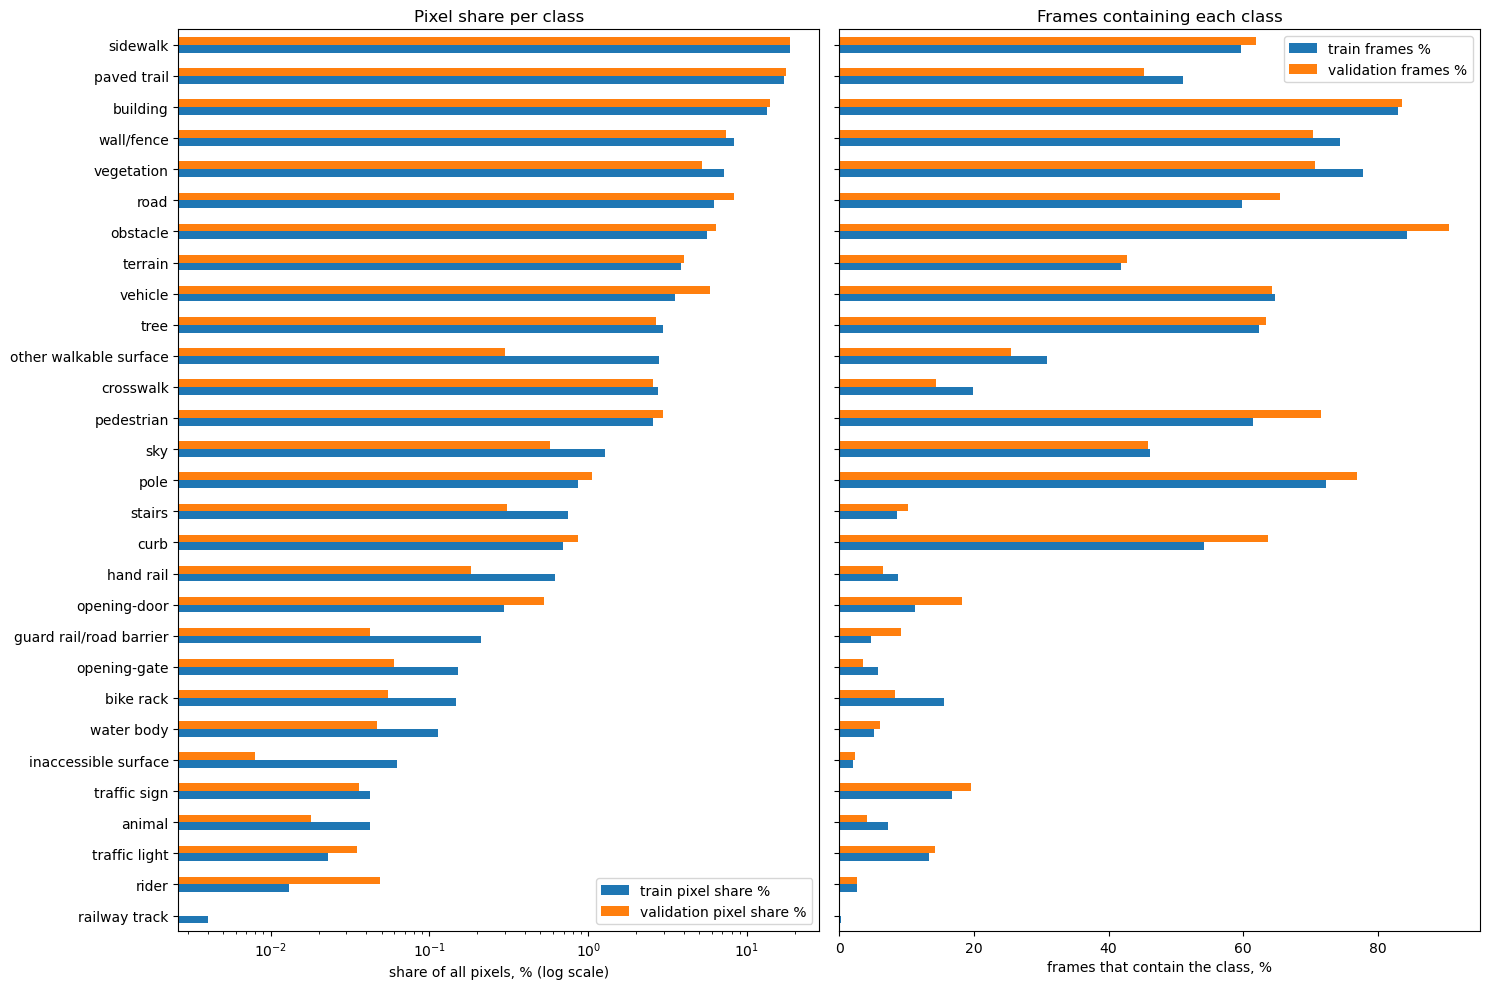

In [10]:
ordered = class_comparison.sort_values("train pixel share %")
figure, axes = plt.subplots(1, 2, figsize=(15, 10), sharey=True)
ordered[["train pixel share %", "validation pixel share %"]].plot(kind="barh", ax=axes[0], logx=True)
axes[0].set_xlabel("share of all pixels, % (log scale)")
axes[0].set_title("Pixel share per class")
ordered[["train frames %", "validation frames %"]].plot(kind="barh", ax=axes[1])
axes[1].set_xlabel("frames that contain the class, %")
axes[1].set_title("Frames containing each class")
plt.tight_layout()
plt.show()

## 9. Comparison: walk attributes (SANPO's descriptions)

Share of walks with each value. A walk can have several environment types and weather conditions.


environment types


,train %,validation %
indoor,1.9,0.0
open space,11.5,8.3
open terrain,7.7,8.3
park,10.6,8.3
road junction,31.7,33.3
rural,1.0,0.0
suburban,8.7,8.3
urban,86.5,91.7



weather


,train %,validation %
cloudy,2.9,0.0
snowy,36.5,33.3
sunny,100.0,100.0



motion blur (SANPO)


,train %,validation %
low,96.2,100.0
medium,3.8,0.0



human traffic


,train %,validation %
low,54.8,41.7
moderate,39.4,41.7
heavy,5.8,16.7


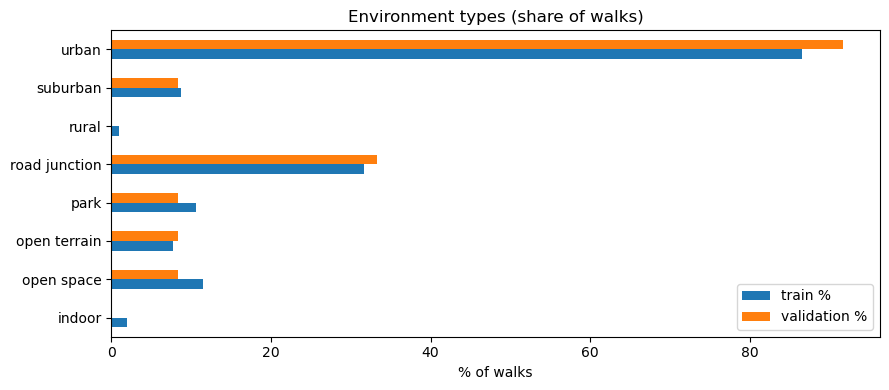

In [11]:
def attribute_shares(column):
    """Share of train and validation walks with each value of one attribute."""
    counts = {}
    for name, mask in [("train %", ~is_chosen), ("validation %", is_chosen)]:
        values = walk_attributes.loc[np.array(sessions)[mask], column]
        flat = []
        for value in values:
            flat.extend(value if isinstance(value, list) else [value])
        counts[name] = (100 * pd.Series(flat).value_counts() / mask.sum()).round(1)
    return pd.DataFrame(counts).fillna(0)


for column in ["environment types", "weather", "motion blur (SANPO)", "human traffic"]:
    print(f"\n{column}")
    display(attribute_shares(column))

attribute_shares("environment types").plot(kind="barh", figsize=(9, 4), title="Environment types (share of walks)")
plt.xlabel("% of walks")
plt.tight_layout()
plt.show()

## 10. Comparison: sharpness

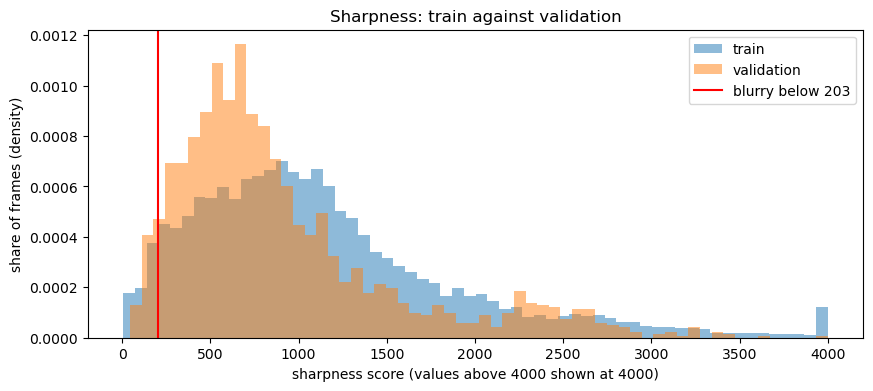

In [12]:
figure, axis = plt.subplots(figsize=(10, 4))
for name, mask in [("train", ~frames["session"].isin(chosen_walks)), ("validation", frames["session"].isin(chosen_walks))]:
    axis.hist(frames.loc[mask, "score"].clip(upper=4000), bins=60, density=True, alpha=0.5, label=name)
axis.axvline(blurry_score, color="red", label=f"blurry below {blurry_score:.0f}")
axis.set_xlabel("sharpness score (values above 4000 shown at 4000)")
axis.set_ylabel("share of frames (density)")
axis.set_title("Sharpness: train against validation")
axis.legend()
plt.show()